# ConvNeXt cattle model: PTH → ONNX, then test on GitHub images

1. **Cell 1-2:** converts `convnext_cattle_best.pth` (in `Cow_lumpy_skin/runs_convnext`) to `convnext_cattle_best.onnx` in the same folder.
2. **Cell 3:** downloads the test images from the two GitHub folders (`Lumpy Skin`, `Normal Skin`) and runs the ONNX model on them (CPU).

A **CPU runtime is enough** for this notebook (`Runtime → Change runtime type → None/CPU`), which saves your free GPU quota. Every test image is resized to 640×640 **in memory only**.

## 1. Convert `.pth` → `.onnx`

In [7]:
!pip install -q timm onnx onnxruntime
import os, json, shutil
import numpy as np
import torch, timm
from google.colab import drive
drive.mount('/content/drive')

os.chdir('/content/drive/MyDrive/Cow_lumpy_skin/runs_convnext')

# ---- EDIT IF NEEDED ----
PTH_NAME  = 'convnext_cattle_best.pth'
ONNX_NAME = 'convnext_cattle_best.onnx'
OPSET     = 17
# ------------------------

def load_checkpoint(path):
    try:
        return torch.load(path, map_location='cpu', weights_only=True)
    except Exception:
        return torch.load(path, map_location='cpu', weights_only=False)   # your own file only

ck = load_checkpoint(PTH_NAME)
state       = ck['model'] if 'model' in ck else ck
class_names = ck.get('class_names') or ['Class_1', 'Class_2']
model_name  = ck.get('model_name') or 'convnext_base.fb_in22k_ft_in1k'
size        = ck.get('img_size') or 640
if 'epoch' in ck:
    print(f"Checkpoint from epoch {ck['epoch'] + 1} | best val loss so far: {ck.get('best_val_loss')}")

model = timm.create_model(model_name, pretrained=False, num_classes=len(class_names))
model.load_state_dict(state)
model.eval()
del ck, state
print(f"Rebuilt {model_name} | classes: {class_names} | input: {size}x{size}")

# Export to fast LOCAL disk first, then copy into Drive (one in-place overwrite, no temp files on Drive)
LOCAL_ONNX = '/content/' + ONNX_NAME
dummy = torch.randn(1, 3, size, size)
kwargs = dict(input_names=['input'], output_names=['logits'],
              dynamic_axes={'input': {0: 'batch'}, 'logits': {0: 'batch'}},
              opset_version=OPSET, do_constant_folding=True)
print("Exporting to ONNX (1-3 minutes on CPU) ...")
with torch.no_grad():
    try:
        torch.onnx.export(model, dummy, LOCAL_ONNX, dynamo=False, **kwargs)
    except TypeError:
        torch.onnx.export(model, dummy, LOCAL_ONNX, **kwargs)

# Embed class names / size / normalization inside the ONNX file
import onnx
m = onnx.load(LOCAL_ONNX)
for k, v in {'class_names': json.dumps(class_names), 'img_size': str(size),
             'mean': '0.485,0.456,0.406', 'std': '0.229,0.224,0.225', 'model_name': model_name}.items():
    entry = m.metadata_props.add(); entry.key, entry.value = k, v
onnx.checker.check_model(m)
onnx.save(m, LOCAL_ONNX)
del m

# Verify: PyTorch vs ONNX Runtime on the same random input
import onnxruntime as ort
x = np.random.RandomState(0).randn(1, 3, size, size).astype(np.float32)
with torch.no_grad():
    ref = model(torch.from_numpy(x)).numpy()
sess = ort.InferenceSession(LOCAL_ONNX, providers=['CPUExecutionProvider'])
got = sess.run(None, {sess.get_inputs()[0].name: x})[0]
diff = float(np.abs(ref - got).max())
print(f"Max |PyTorch - ONNX| logit difference: {diff:.2e} ({'OK' if diff < 1e-3 else 'larger than expected, check export'})")

shutil.copyfile(LOCAL_ONNX, os.path.join(os.getcwd(), ONNX_NAME))
print(f"Saved to Drive: {os.path.join(os.getcwd(), ONNX_NAME)} ({os.path.getsize(LOCAL_ONNX)/1024**2:.0f} MB)")
del model, sess

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 26.0 MB/s eta 0:00:00
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoint from epoch 92 | best val loss so far: 0.20005092663424356
Rebuilt convnext_base.fb_in22k_ft_in1k | classes: ['Class_1', 'Class_2'] | input: 640x640
Exporting to ONNX (1-3 minutes on CPU) ...


/tmp/ipykernel_2869/292400640.py:45: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy, LOCAL_ONNX, dynamo=False, **kwargs)


Max |PyTorch - ONNX| logit difference: 1.40e-06 (OK)
Saved to Drive: /content/drive/MyDrive/Cow_lumpy_skin/runs_convnext/convnext_cattle_best.onnx (334 MB)


## 2. Test the ONNX model on the GitHub test images
Downloads the images from both GitHub folders (via the GitHub API), runs the ONNX model on CPU, and shows predictions.

**Set `FOLDER_TRUE_CLASS`** to tell the notebook which class each GitHub folder represents (e.g. `'Class_2'`), so accuracy can be computed. If you leave it as `None`, you still get a table of how many images from each folder were predicted as each class. Your training folders were named `Class_1` / `Class_2`, so the mapping to *Lumpy Skin* / *Normal Skin* is yours to fill in.

In [8]:
!pip install -q onnxruntime
import os, re, json, time, urllib.parse
import requests
import numpy as np
import pandas as pd
import onnxruntime as ort
import matplotlib.pyplot as plt
from PIL import Image

ONNX_PATH = '/content/drive/MyDrive/Cow_lumpy_skin/runs_convnext/convnext_cattle_best.onnx'

GITHUB_FOLDERS = [
    'https://github.com/Diagopreutic/LumpyGuard/tree/main/test_images/Lumpy%20Skin',
    'https://github.com/Diagopreutic/LumpyGuard/tree/main/test_images/Normal%20Skin',
]
# Which model class does each GitHub folder correspond to? e.g. 'Class_2'. None = unknown.
FOLDER_TRUE_CLASS = {'Lumpy Skin': None, 'Normal Skin': None}

EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
DEST_ROOT = '/content/test_images'
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
RESAMPLE = getattr(Image, 'Resampling', Image).BILINEAR

# ---------- 1) download the images ----------
def download_folder(url):
    m = re.match(r'https://github\.com/([^/]+)/([^/]+)/tree/([^/]+)/(.+)$', url.rstrip('/'))
    assert m, f"Not a GitHub folder URL: {url}"
    owner, repo, ref, path = m.groups()
    path = urllib.parse.unquote(path)
    api = f'https://api.github.com/repos/{owner}/{repo}/contents/{urllib.parse.quote(path)}'
    r = requests.get(api, params={'ref': ref}, timeout=30)
    if r.status_code != 200:
        raise RuntimeError(f"GitHub API returned {r.status_code} for {path}. "
                           f"Check that the repo/folder is public and the URL is right. {r.text[:200]}")
    items = [i for i in r.json() if i.get('type') == 'file' and i['name'].lower().endswith(EXTS)]
    folder = os.path.basename(path)
    out_dir = os.path.join(DEST_ROOT, folder)
    os.makedirs(out_dir, exist_ok=True)
    for it in items:
        dst = os.path.join(out_dir, it['name'])
        if not os.path.exists(dst):
            with open(dst, 'wb') as f:
                f.write(requests.get(it['download_url'], timeout=60).content)
    print(f"{folder}: {len(items)} image(s) -> {out_dir}")
    return folder, out_dir

folders = dict(download_folder(u) for u in GITHUB_FOLDERS)   # {'Lumpy Skin': dir, 'Normal Skin': dir}

# ---------- 2) load the ONNX model ----------
sess = ort.InferenceSession(ONNX_PATH, providers=['CPUExecutionProvider'])
inp = sess.get_inputs()[0]
meta = sess.get_modelmeta().custom_metadata_map
class_names = json.loads(meta['class_names']) if 'class_names' in meta else ['Class_1', 'Class_2']
size = inp.shape[2] if isinstance(inp.shape[2], int) else int(meta.get('img_size', 640))
print(f"\nModel loaded | classes: {class_names} | input: {size}x{size} | CPU")
print(f"\nClass_1 -> Lumpy_skin         Class_2 -> Normal_skin\n")

def preprocess(path):
    with Image.open(path) as im:                      # original file is never modified
        im = im.convert('RGB').resize((size, size), RESAMPLE)
    a = (np.asarray(im, dtype=np.float32) / 255.0 - MEAN) / STD
    return np.ascontiguousarray(a.transpose(2, 0, 1)[None], dtype=np.float32)

def softmax(z):
    e = np.exp(z - z.max()); return e / e.sum()

# ---------- 3) run inference ----------
rows, t0 = [], time.time()
for folder, d in folders.items():
    for fn in sorted(os.listdir(d)):
        if not fn.lower().endswith(EXTS): continue
        p = os.path.join(d, fn)
        probs = softmax(sess.run(None, {inp.name: preprocess(p)})[0][0])
        k = int(probs.argmax())
        rows.append(dict(folder=folder, file=fn, path=p, pred=class_names[k], conf=float(probs[k]),
                         **{f'p_{c}': float(pr) for c, pr in zip(class_names, probs)}))
        print(f"{folder:12s} | {fn[:40]:40s} -> {class_names[k]} ({probs[k]*100:.1f}%)")
print(f"\n{len(rows)} images in {time.time() - t0:.1f}s")

df = pd.DataFrame(rows)
print("\nPredictions per GitHub folder:")
display(pd.crosstab(df['folder'], df['pred']))

# accuracy, if you told the notebook which class each folder stands for
known = df[df['folder'].map(FOLDER_TRUE_CLASS).notna()]
if len(known):
    truth = known['folder'].map(FOLDER_TRUE_CLASS)
    acc = (known['pred'] == truth).mean()
    print(f"Accuracy on {len(known)} images: {acc:.4f}")
    wrong = known[known['pred'] != truth]
    if len(wrong): display(wrong[['folder', 'file', 'pred', 'conf']])
else:
    print("Set FOLDER_TRUE_CLASS above to also get accuracy.")

df.drop(columns='path').to_csv('/content/drive/MyDrive/Cow_lumpy_skin/runs_convnext/github_test_results.csv', index=False)

# ---------- 4) preview ----------
sample = df.sample(min(12, len(df)), random_state=0)
cols = 4; rws = int(np.ceil(len(sample) / cols))
fig, axs = plt.subplots(rws, cols, figsize=(4 * cols, 3.6 * rws))
for ax in np.atleast_1d(axs).ravel(): ax.axis('off')
for ax, (_, r) in zip(np.atleast_1d(axs).ravel(), sample.iterrows()):
    ax.imshow(Image.open(r['path']).convert('RGB'))
    ax.set_title(f"{r['folder']}\n-> {r['pred']} ({r['conf']*100:.0f}%)", fontsize=10)
plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

## 3. Load the ONNX model from GitHub (run once)
Downloads `convnext_cattle_best.onnx` from the GitHub repo **into memory** and keeps it there for the rest of the session. Run this cell **once**: the next cell can then be re-run as often as you like without downloading the model again. (If the runtime restarts or disconnects, run this cell again.)

In [1]:
!pip install -q onnxruntime
import io, json, time
import requests
import onnxruntime as ort

# ============================ EDIT THESE ============================
GITHUB_ONNX_URL = 'https://github.com/Diagopreutic/LumpyGuard/blob/main/convnext_cattle_best.onnx'
FORCE_RELOAD = False      # True = download the model again even if it is already loaded
# ====================================================================

if globals().get('GH_LOADED_URL') == GITHUB_ONNX_URL and not FORCE_RELOAD:
    print("Model already loaded in this session, skipping the download. (Set FORCE_RELOAD = True to reload.)")
else:
    # ---------- 1) download the ONNX model into memory ----------
    raw_url = GITHUB_ONNX_URL.replace('/blob/', '/raw/', 1)      # the /raw/ form also serves Git LFS files
    print("Downloading ONNX model ...")
    r = requests.get(raw_url, stream=True, timeout=60)
    if r.status_code != 200:
        raise RuntimeError(f"Could not download the ONNX file (HTTP {r.status_code}). Is the repo public and the path correct?")
    buf, done, t0 = io.BytesIO(), 0, time.time()
    for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
        buf.write(chunk); done += len(chunk)
        print(f"\r  {done / 1024**2:.0f} MB", end='')
    onnx_bytes = buf.getvalue(); del buf
    print(f"\nDownloaded {len(onnx_bytes) / 1024**2:.0f} MB in {time.time() - t0:.0f}s")
    if onnx_bytes[:40].startswith(b'version https://git-lfs') or len(onnx_bytes) < 1024 * 1024:
        raise RuntimeError("Got a Git LFS pointer or a tiny file instead of the real model. "
                           "Check that the ONNX file in the repo is the full model.")

    gh_sess = ort.InferenceSession(onnx_bytes, providers=['CPUExecutionProvider'])
    del onnx_bytes
    gh_inp = gh_sess.get_inputs()[0]
    meta = gh_sess.get_modelmeta().custom_metadata_map
    gh_classes = json.loads(meta['class_names']) if 'class_names' in meta else ['Class_1', 'Class_2']
    gh_size = gh_inp.shape[2] if isinstance(gh_inp.shape[2], int) else int(meta.get('img_size', 640))
    print(f"Model loaded | classes: {gh_classes} | input: {gh_size}x{gh_size} | CPU\n")
    print(f"Class_1 -> Lumpy_skin         Class_2 -> Normal_skin\n")
    GH_LOADED_URL = GITHUB_ONNX_URL

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 44.8 MB/s eta 0:00:00
  334 MB
Downloaded 334 MB in 24s
Model loaded | classes: ['Class_1', 'Class_2'] | input: 640x640 | CPU

Class_1 -> Lumpy_skin         Class_2 -> Normal_skin



## 4. Test images from any link or path (re-run freely)
Tests the images listed in **`INPUT_PATHS`**. By default these are the two GitHub test folders; edit the list to test your own. Each entry can be:

- a **GitHub folder or image link** (`.../tree/...` or `.../blob/...`)
- a **Google Drive folder or image file path** (e.g. `/content/drive/MyDrive/...`; Drive is mounted automatically)
- a **shared Google Drive link** (folder or file, set to "Anyone with the link"; these are saved temporarily and deleted at the end)
- a **direct image URL**, or a **folder/file in Colab** (e.g. `/content/my_images`)

**Results are only printed** (no CSV or other output file).

In [2]:
from google.colab import drive
import os
drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/Cow_lumpy_skin')

Mounted at /content/drive


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder  /content/drive/MyDrive/Cow_lumpy_skin/new_test/: 2 image(s)

Class_1 -> Lumpy_skin         Class_2 -> Normal_skin


Testing 2 image(s) ...

new_test       | Lumpy_Skin_72_png.rf.bd1af912c1e34987d8f -> Class_1 (95.7%)
new_test       | Normal_Skin_381_png.rf.4704594595fd9e82b -> Class_2 (93.4%)

2 images in 7.3s

Predictions per folder:


pred,Class_1,Class_2
group,,
new_test,1,1


Set FOLDER_TRUE_CLASS above (or use folders named like the classes) to also get accuracy.


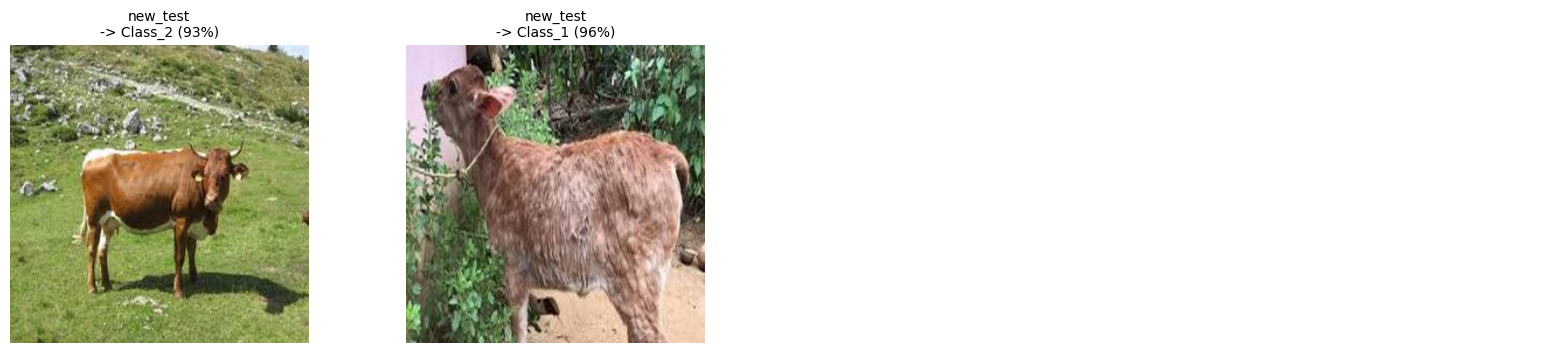

In [5]:
!pip install -q gdown
import io, os, re, json, time, shutil, tempfile, urllib.parse
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

if 'GH_LOADED_URL' not in globals():
    raise RuntimeError("The ONNX model is not loaded yet. Run the previous cell (model download) first.")

# ============================ EDIT THESE ============================
INPUT_PATHS = [                      # image files and/or folders, local paths or links
    #'https://github.com/Diagopreutic/LumpyGuard/tree/main/test_images/Lumpy%20Skin',
    #'https://github.com/Diagopreutic/LumpyGuard/tree/main/test_images/Normal%20Skin',
    # ---- other things you can add (remove the # to use) ----
     '/content/drive/MyDrive/Cow_lumpy_skin/new_test/',               # Google Drive folder
    # '/content/drive/MyDrive/Cow_lumpy_skin/new_test/Lumpy_Skin_72_png.rf.bd1af912c1e34987d8fb81c24e87e13e.jpg',                  # Google Drive image file
    # 'https://drive.google.com/drive/folders/FOLDER_ID',        # shared Drive folder link
    # 'https://drive.google.com/file/d/FILE_ID/view',            # shared Drive image link
    # 'https://github.com/USER/REPO/blob/main/images/cow.jpg',   # GitHub image file
    # 'https://example.com/cow.jpg',                             # direct image URL
    # '/content/my_images',                                      # folder or file already in Colab
]

# Optional: which model class does each folder stand for? (the folder name an image sits in)
# Folders named exactly like a class (e.g. Class_1, Class_2) are matched automatically.
FOLDER_TRUE_CLASS = {'Lumpy Skin': None, 'Normal Skin': None}   # e.g. {'Lumpy Skin': 'Class_2', 'Normal Skin': 'Class_1'}
# ====================================================================

EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
RESAMPLE = getattr(Image, 'Resampling', Image).BILINEAR
is_img = lambda name: name.lower().split('?')[0].endswith(EXTS)

if any(str(p).startswith('/content/drive') for p in INPUT_PATHS):
    from google.colab import drive
    drive.mount('/content/drive')

# ---------- 2) collect the images from INPUT_PATHS ----------
items, seen, tmp_dirs = [], set(), []      # item = {group, name, src}; src is bytes (downloaded) or a file path

def add(group, name, src, key):
    if key not in seen:
        seen.add(key); items.append(dict(group=group, name=name, src=src))

def github_list(owner, repo, ref, path):
    api = f'https://api.github.com/repos/{owner}/{repo}/contents/{urllib.parse.quote(path)}'
    resp = requests.get(api, params={'ref': ref}, timeout=30)
    if resp.status_code != 200:
        raise RuntimeError(f"GitHub API returned {resp.status_code} for '{path}'. {resp.text[:150]}")
    data = resp.json()
    for e in ([data] if isinstance(data, dict) else data):          # a single file comes back as a dict
        if e['type'] == 'dir':
            yield from github_list(owner, repo, ref, e['path'])
        elif e['type'] == 'file' and is_img(e['name']):
            yield os.path.basename(os.path.dirname(e['path'])), e['name'], e['download_url']

def add_input(p):
    p = str(p).strip()
    gh = re.match(r'https://github\.com/([^/]+)/([^/]+)/(?:tree|blob|raw)/([^/]+)/(.+)$', p.rstrip('/'))
    if gh:                                                             # GitHub folder or image file
        owner, repo, ref, path = gh.groups()
        path = urllib.parse.unquote(path.split('?')[0])
        n = 0
        for group, name, url in github_list(owner, repo, ref, path):
            add(group, name, requests.get(url, timeout=60).content, url); n += 1
        print(f"GitHub  {path}: {n} image(s)")
    elif 'drive.google.com' in p:                                      # shared Google Drive link
        import gdown
        d = tempfile.mkdtemp(); tmp_dirs.append(d)
        fm = re.search(r'/folders/([\w-]+)', p)
        if fm:
            gdown.download_folder(id=fm.group(1), output=d, quiet=True, use_cookies=False, remaining_ok=True)
        else:
            im = re.search(r'/d/([\w-]+)', p) or re.search(r'[?&]id=([\w-]+)', p)
            if not im: raise ValueError("Could not find a file or folder id in this Drive link")
            gdown.download(id=im.group(1), output=d + os.sep, quiet=True)
        n = 0
        for dirpath, _, files in os.walk(d):
            for f in sorted(files):
                if is_img(f):
                    group = os.path.basename(dirpath) if dirpath != d else 'Drive files'
                    add(group, f, os.path.join(dirpath, f), os.path.join(dirpath, f)); n += 1
        print(f"Drive link {p[:60]}...: {n} image(s)")
        if n == 0: print("   (nothing found: the link must be shared as 'Anyone with the link'; "
                         "for private files use the mounted path /content/drive/MyDrive/... instead)")
    elif p.startswith(('http://', 'https://')):                       # direct image URL
        path = urllib.parse.urlparse(p).path
        if not is_img(path): raise ValueError("Not a direct image URL (.jpg/.png/...)")
        resp = requests.get(p, timeout=60); resp.raise_for_status()
        add('Web images', os.path.basename(urllib.parse.unquote(path)) or 'image', resp.content, p)
        print(f"URL     {p[:70]}: 1 image")
    elif os.path.isdir(p):                                             # local / mounted-Drive folder
        n = 0
        for dirpath, _, files in os.walk(p):
            for f in sorted(files):
                if is_img(f):
                    add(os.path.basename(dirpath.rstrip('/')), f, os.path.join(dirpath, f), os.path.join(dirpath, f)); n += 1
        print(f"Folder  {p}: {n} image(s)")
    elif os.path.isfile(p):                                            # local / mounted-Drive image file
        if not is_img(p): raise ValueError("Not an image file (.jpg/.png/...)")
        add(os.path.basename(os.path.dirname(os.path.abspath(p))), os.path.basename(p), p, p)
        print(f"File    {p}")
    else:
        raise FileNotFoundError("Path not found (for Google Drive paths, check the folder name and that Drive is mounted)")

for p in INPUT_PATHS:
    try:
        add_input(p)
    except Exception as e:
        print(f"[skipped] {p}\n   -> {e}")
if not items:
    raise RuntimeError("No images found. Check INPUT_PATHS.")

def get_bytes(src):
    if isinstance(src, bytes): return src
    with open(src, 'rb') as f: return f.read()

def preprocess(img_bytes):
    with Image.open(io.BytesIO(img_bytes)) as im:         # resized in memory only; originals never modified
        im = im.convert('RGB').resize((gh_size, gh_size), RESAMPLE)
    a = (np.asarray(im, dtype=np.float32) / 255.0 - MEAN) / STD
    return np.ascontiguousarray(a.transpose(2, 0, 1)[None], dtype=np.float32)

def softmax(z):
    e = np.exp(z - z.max()); return e / e.sum()

# ---------- 3) run inference and print ----------
print(f"\nClass_1 -> Lumpy_skin         Class_2 -> Normal_skin\n")
print(f"\nTesting {len(items)} image(s) ...\n")
rows, t0 = [], time.time()
for i, it in enumerate(items):
    try:
        probs = softmax(gh_sess.run(None, {gh_inp.name: preprocess(get_bytes(it['src']))})[0][0])
    except Exception as e:
        print(f"[skipped] {it['name']}: {e}"); continue
    k = int(probs.argmax())
    rows.append(dict(idx=i, group=it['group'], file=it['name'], pred=gh_classes[k], conf=float(probs[k]),
                     **{f'p_{c}': float(pr) for c, pr in zip(gh_classes, probs)}))
    print(f"{it['group'][:14]:14s} | {it['name'][:40]:40s} -> {gh_classes[k]} ({probs[k]*100:.1f}%)")
print(f"\n{len(rows)} images in {time.time() - t0:.1f}s")

df = pd.DataFrame(rows)
print("\nPredictions per folder:")
display(pd.crosstab(df['group'], df['pred']))

def true_class(group):
    t = FOLDER_TRUE_CLASS.get(group)
    return t if t else (group if group in gh_classes else None)

df['truth'] = df['group'].map(true_class)
known = df[df['truth'].notna()]
if len(known):
    print(f"Accuracy on {len(known)} images with a known class: {(known['pred'] == known['truth']).mean():.4f}")
    wrong = known[known['pred'] != known['truth']]
    if len(wrong): display(wrong[['group', 'file', 'pred', 'conf']])
else:
    print("Set FOLDER_TRUE_CLASS above (or use folders named like the classes) to also get accuracy.")

# ---------- 4) preview (shown only, not saved) ----------
sample = df.sample(min(12, len(df)), random_state=0)
cols = 4; rws = int(np.ceil(len(sample) / cols))
fig, axs = plt.subplots(rws, cols, figsize=(4 * cols, 3.6 * rws))
for ax in np.atleast_1d(axs).ravel(): ax.axis('off')
for ax, (_, r_) in zip(np.atleast_1d(axs).ravel(), sample.iterrows()):
    ax.imshow(Image.open(io.BytesIO(get_bytes(items[r_['idx']]['src']))).convert('RGB'))
    ax.set_title(f"{r_['group'][:22]}\n-> {r_['pred']} ({r_['conf']*100:.0f}%)", fontsize=10)
plt.tight_layout(); plt.show()

for d in tmp_dirs:                      # remove temporary files from shared Drive links
    shutil.rmtree(d, ignore_errors=True)